# Principal Component Analysis of Breast Cancer Referrals

**Anderson Cancer Center**

The center is facing a growing number of referrals. As a first step toward a model that supports donor funding, this notebook finds the variables that matter most in the referral data using **Principal Component Analysis (PCA)**.

The work runs as a reproducible **Apache Spark (PySpark)** pipeline:

1. **Load** the raw referral file with an explicit schema
2. **Clean:** remove duplicate records and resolve missing values
3. **Prepare:** combine the 30 measurements into one feature vector and standardise it
4. **PCA:** reduce the features to 2 principal components and report the variance each explains
5. **Bonus:** logistic regression on the 2 components to predict the diagnosis

In [41]:
# %pip install pyspark
# %pip install pandas
# %pip install matplotlib

In [56]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.feature import PCA, Imputer, StandardScaler, VectorAssembler
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, StringType, StructField, StructType

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
DATA_FILE = "breast_cancer_referrals.csv"
N_COMPONENTS = 2
TEST_FRACTION = 0.2
DIAGNOSIS_COLORS = {"Benign": "#2a78d6", "Malignant": "#eb6834"}   # Colour-blind-safe pair

os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")    # Run Spark on this machine only
spark = (SparkSession.builder
         .appName("BreastCancerReferralsPCA")
         .master("local[*]")
         .config("spark.driver.host", "127.0.0.1")          # Avoids hostname issues on laptops
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.sql.shuffle.partitions", "8")        # Small data: avoid 200 tiny partitions
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version} running locally")

Spark 4.2.0 running locally


## 1. Load the data with an explicit schema

Every column's name and type is declared up front, rather than letting Spark guess:

- `patient_id` and `diagnosis` are text.
- The 30 cell measurements are decimals: the **mean**, **standard error** and **worst** (largest) value of 10 cell-nucleus features.

`enforceSchema=False` makes Spark check that the file's header matches the schema. `mode="FAILFAST"` stops the load on any badly formatted value instead of silently turning it into a blank.

In [57]:
FEATURES = ["radius", "texture", "perimeter", "area", "smoothness",
            "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
FEATURE_COLUMNS = ([f"mean_{f}" for f in FEATURES]
                   + [f"{f}_error" for f in FEATURES]
                   + [f"worst_{f}" for f in FEATURES])

REFERRAL_SCHEMA = StructType(
    [StructField("patient_id", StringType(), nullable=True)]
    + [StructField(column, DoubleType(), nullable=True) for column in FEATURE_COLUMNS]
    + [StructField("diagnosis", StringType(), nullable=True)]
)

raw_df = spark.read.csv(DATA_FILE, header=True, schema=REFERRAL_SCHEMA,
                        enforceSchema=False, mode="FAILFAST")
raw_df.printSchema()

root
 |-- patient_id: string (nullable = true)
 |-- mean_radius: double (nullable = true)
 |-- mean_texture: double (nullable = true)
 |-- mean_perimeter: double (nullable = true)
 |-- mean_area: double (nullable = true)
 |-- mean_smoothness: double (nullable = true)
 |-- mean_compactness: double (nullable = true)
 |-- mean_concavity: double (nullable = true)
 |-- mean_concave_points: double (nullable = true)
 |-- mean_symmetry: double (nullable = true)
 |-- mean_fractal_dimension: double (nullable = true)
 |-- radius_error: double (nullable = true)
 |-- texture_error: double (nullable = true)
 |-- perimeter_error: double (nullable = true)
 |-- area_error: double (nullable = true)
 |-- smoothness_error: double (nullable = true)
 |-- compactness_error: double (nullable = true)
 |-- concavity_error: double (nullable = true)
 |-- concave_points_error: double (nullable = true)
 |-- symmetry_error: double (nullable = true)
 |-- fractal_dimension_error: double (nullable = true)
 |-- worst_ra

In [58]:
print(f"Loaded {raw_df.count():,} rows x {len(raw_df.columns)} columns")
raw_df.select("patient_id", "mean_radius", "mean_texture", "worst_area", "diagnosis").show(5)

Loaded 572 rows x 32 columns
+----------+-----------+------------+----------+---------+
|patient_id|mean_radius|mean_texture|worst_area|diagnosis|
+----------+-----------+------------+----------+---------+
|  PT-00001|      17.99|       10.38|    2019.0|        M|
|  PT-00002|      20.57|       17.77|    1956.0|        M|
|  PT-00003|      19.69|       21.25|    1709.0|        M|
|  PT-00004|      11.42|       20.38|     567.7|        M|
|  PT-00005|      20.29|       14.34|    1575.0|        M|
+----------+-----------+------------+----------+---------+
only showing top 5 rows


## 2. Clean the data

### Duplicates

Some referrals were exported more than once. Exact duplicate rows are removed, and a check confirms every remaining `patient_id` is unique.

In [59]:
repeated_ids_count = raw_df.groupBy("patient_id").count().filter("count > 1").count()
print(f"Patient IDs repeated: {repeated_ids_count}")
deduped_df = raw_df.dropDuplicates()
still_repeated_ids_count = deduped_df.groupBy("patient_id").count().filter("count > 1").count()

print(f"Rows before: {raw_df.count():,} | after removing duplicates: {deduped_df.count():,} "
      f"({raw_df.count() - deduped_df.count()} removed)")
print(f"Patient IDs still repeated: {still_repeated_ids_count}")

Patient IDs repeated: 3
Rows before: 572 | after removing duplicates: 569 (3 removed)
Patient IDs still repeated: 0


### Missing values

Count the blanks in each column:

In [60]:
def count_missing(df):
    """Return a one-row DataFrame with the number of nulls in each column that has any."""
    counts = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
    return pd.DataFrame({k: [v] for k, v in counts.items() if v}, index=["missing"])


count_missing(deduped_df)

,mean_radius,mean_texture,worst_area
missing,6,6,6


Only three measurements have gaps, each about 1% of rows, so the missing values are resolved like this:

- **Measurements** are filled with the column **median** using Spark's `Imputer`. The median isn't distorted by the long right tail of size measurements such as area.
- **Diagnosis:** any row missing one is dropped, because the outcome can't be filled in like we did for the measurement columns. There are none in this file, but the step keeps the pipeline safe for future exports.

The diagnosis is also converted to a numeric `label`: **1 = Malignant (M)** and **0 = Benign (B)**.

In [61]:
clean_df = (deduped_df
            .dropna(subset=["diagnosis"])
            .withColumn("label", F.when(F.col("diagnosis") == "M", 1.0).otherwise(0.0)))

imputer = Imputer(strategy="median", inputCols=FEATURE_COLUMNS, outputCols=FEATURE_COLUMNS)
clean_df = imputer.fit(clean_df).transform(clean_df).cache()

print(f"Clean rows: {clean_df.count():,} | missing values remaining: {int(count_missing(clean_df).to_numpy().sum())}")
clean_df.groupBy("diagnosis").count().orderBy("diagnosis").show()

Clean rows: 569 | missing values remaining: 0
+---------+-----+
|diagnosis|count|
+---------+-----+
|        B|  357|
|        M|  212|
+---------+-----+



## 3. Assemble and standardise the features

The 30 measurements are on very different scales: area runs into the thousands while smoothness is below 0.2. Without scaling, PCA would be dominated by the largest numbers.

- `VectorAssembler` combines the 30 columns into one `features` vector.
- `StandardScaler` rescales each feature to **mean 0 and standard deviation 1**.

Both are stages of a Spark ML `Pipeline`, so the exact same preparation can be rerun on new referral data.

In [62]:
assembler = VectorAssembler(inputCols=FEATURE_COLUMNS, outputCol="features")
scaler = StandardScaler(inputCol="features", outputCol="scaled_features", withMean=True, withStd=True)
pca = PCA(k=N_COMPONENTS, inputCol="scaled_features", outputCol="pca_features")

pca_pipeline = Pipeline(stages=[assembler, scaler, pca])
pca_model = pca_pipeline.fit(clean_df)
prepared_df = pca_model.transform(clean_df)

prepared_df.select("patient_id", "features", "scaled_features").show(5, truncate=70)

+----------+----------------------------------------------------------------------+----------------------------------------------------------------------+
|patient_id|                                                              features|                                                       scaled_features|
+----------+----------------------------------------------------------------------+----------------------------------------------------------------------+
|  PT-00006|[12.45,15.7,82.57,477.1,0.1278,0.17,0.1578,0.08089,0.2087,0.07613,0...|[-0.47989195525108874,-0.8349957159548227,-0.3868077174481085,-0.50...|
|  PT-00017|[14.68,20.13,94.74,684.5,0.09867,0.072,0.07395,0.05259,0.1586,0.059...|[0.15463884774821493,0.20114232658647652,0.11403632949319495,0.0841...|
|  PT-00026|[17.14,16.4,116.0,912.7,0.1186,0.2276,0.2229,0.1401,0.304,0.07413,1...|[0.8546145317743528,-0.6712718717609382,0.9889701370504761,0.732596...|
|  PT-00030|[17.57,15.05,115.0,955.1,0.09847,0.1157,0.09875,0.07953,0.

## 4. Principal Component Analysis

### Explained variance

How much of the information in the 30 standardised measurements do the 2 components keep?

In [63]:
# print(pca_model.stages[-1].getOutputCol())
pca_stage = pca_model.stages[-1]
explained = pca_stage.explainedVariance.toArray()

variance_report = pd.DataFrame({
    "explained variance": explained,
    "cumulative": explained.cumsum(),
}, index=[f"PC{i + 1}" for i in range(N_COMPONENTS)])
print(f"PC1 + PC2 together explain {explained.sum():.1%} of the variance in the 30 measurements")
variance_report.map(lambda value: f"{value:.1%}")

PC1 + PC2 together explain 63.2% of the variance in the 30 measurements


,explained variance,cumulative
PC1,44.2%,44.2%
PC2,19.0%,63.2%


### Which variables drive each component?

The **loadings** show how strongly each measurement contributes to a component. The sign only gives direction; size is what matters.

In [95]:
# print(pca_stage.pc.toArray())
loadings = pd.DataFrame(pca_stage.pc.toArray(), index=FEATURE_COLUMNS,
                        columns=[f"PC{i + 1}" for i in range(N_COMPONENTS)])
# print(loadings['PC1'].sort_values().abs())
top_variables = {
    component: loadings[component].abs().sort_values(ascending=False).head(10).index.tolist() for component in loadings.columns
}
pd.DataFrame(top_variables, index=range(1, 11)).rename_axis("rank")

,PC1,PC2
rank,,
1,mean_concave_points,mean_fractal_dimension
2,mean_concavity,fractal_dimension_error
3,worst_concave_points,worst_fractal_dimension
4,mean_compactness,mean_radius
5,worst_perimeter,compactness_error
6,worst_concavity,mean_area
7,worst_radius,worst_radius
8,mean_perimeter,worst_area
9,worst_area,mean_perimeter


### The 2 components plotted

Each point is a patient, coloured by diagnosis.

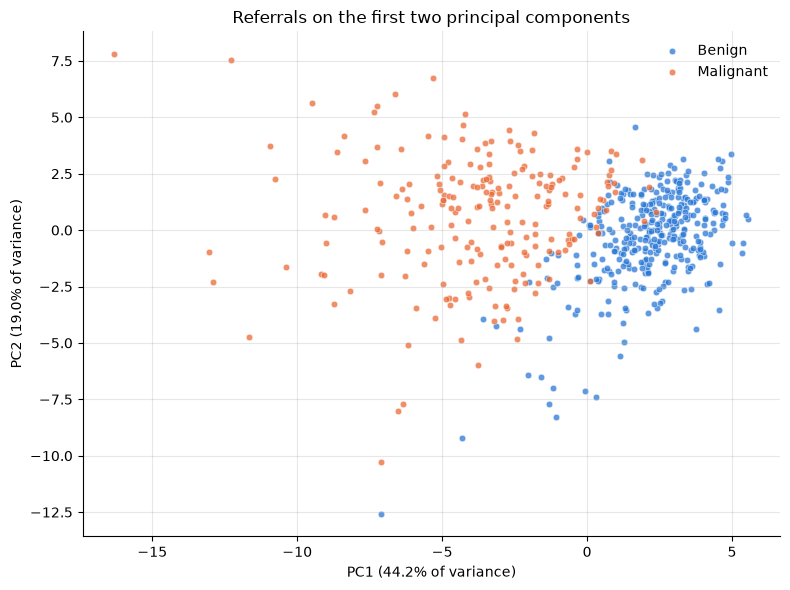

In [51]:
components_pdf = pd.DataFrame(
    prepared_df.select("pca_features", "diagnosis").rdd
    .map(lambda row: (*row.pca_features.toArray().tolist(), row.diagnosis)).collect(),
    columns=["PC1", "PC2", "diagnosis"],
)
components_pdf["diagnosis"] = components_pdf["diagnosis"].map({"B": "Benign", "M": "Malignant"})

fig, ax = plt.subplots(figsize=(8, 6))
for diagnosis, group in components_pdf.groupby("diagnosis"):
    ax.scatter(group["PC1"], group["PC2"], s=22, alpha=0.75, label=diagnosis,
               color=DIAGNOSIS_COLORS[diagnosis], edgecolors="white", linewidths=0.4)
ax.set(title="Referrals on the first two principal components",
       xlabel=f"PC1 ({explained[0]:.1%} of variance)", ylabel=f"PC2 ({explained[1]:.1%} of variance)")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("pca_components.png", dpi=150, bbox_inches="tight")
plt.show()

### What the PCA shows

| Component | Variance explained | Main variables | Interpretation |
|---|---|---|---|
| **PC1** | **44.2%** | concave points, concavity, compactness, perimeter, radius | **Size and shape irregularity** of the cell nuclei |
| **PC2** | **19.0%** | fractal dimension (mean, error, worst), plus radius and area | **Border complexity**, as distinct from size |
| **Total** | **63.2%** | | Two components keep almost two thirds of the information in 30 measurements |

- **PC1 separates the diagnoses.** Malignant referrals sit at one end and benign ones at the other, with only a narrow overlap. The direction of a PCA axis is arbitrary; what matters is the separation.
- **Key variables for the donor-funding model:** the measurements behind PC1, especially **concave points, concavity, compactness and nucleus size** (perimeter, radius, area). These vary most across referrals and line up most closely with diagnosis.

In [54]:
spark.stop()